<ol type="1" style="list-style-type: decimal">
    <li><a href="#1">Introducere</a></li>
    <li><a href="#2">Filtre de ordine</a></li>
    <ol type="1" style="list-style-type: decimal">
        <li><a href="#2-1">Filtru Median</a></li>
        <li><a href="#1-1">Filtru de ordine ponderat</a></li>
    </ol>
    <li><a href="#3">L-Filtre</a></li>
    <li><a href="#4">Morfologie</a></li>
    <ol type="1" style="list-style-type: decimal">
        <li><a href="#4-1">Erodare</a></li>
        <li><a href="#4-2">Dilatare</a></li>
        <li><a href="#4-3">Inchidere</a></li>
        <li><a href="#4-4">Deschidere</a></li>
    </ol>
    <li> <a href="#5">Exercitii</a> </li>
</ol>

<h1 id="1"> 1. Introducere </h1>
<p> Limitarile esentiale ale operatiilor liniare apar atunci cand spre exemplu, distributia zgomotului din imagine nu mai este una normala, si mai mult, acest zgomot nu este aditiv. Un astfel de zgomot este zgomotul de tip impulsiv, caracterizat prin amplitudini maxime sau minime relativ la gama valorilor din imagine, care afecteaza prin inlocuire o parte din pixelii imaginilor, rezultatul fiind ceea ce se numeste zgomot de tip "sare si piper", datorita punctelor foarte deschise ( albe ) si foarte inchise ( negre ) ce inlocuiesc pixelii imaginii. </p>
<p> Aplicarea unei filtrari liniare de netezire asupra unui astfel de zgomot ar avea ca rezultat acentuarea punctelor de zgomot prin "intinderea" lor si corpuerea valorilor corecte din jurul lor, dupa cum putem vedea in Fig. 1 </p>
<figure>
    <center>
        <img src="img/00.png"/>
    </center>
<center>Fig. 1 Rezultatul filtrului de mediere asupra zgomotului tip sare si piper </center>
</figure>
<p> Pentru a putea face operatia de convolutie mai rapid, putem instala biblioteca scipy, lansand anaconda  </p>
<code> conda install scipy </code>

<p> De asemenea, pentru a putea face operatiile de morfologie, putem instala biblioteca opencv, care este una din cele mai populare si puternice biblioteci pentru aplicatii de prelucrare a imaginilor </p>
<code> conda install opencv </code>


<h1 id="2"> 2. Filtre de ordine </h1>

<p> Este astfel necesara o clasa diferita de filtre, neliniare, care nu se mai bazeaza pe principiul superpozitiei, o clasa esentiala a unor astfel de filtre sunt cele de ordonare, care au ca efect impingerea valorilor extreme (outliers) la inceputul sau sfarsitul sirului de valori dintr-o vecinatate </p>

<p> Filtrele de ordine sunt operatori locali: filtrul este definit de o fereastr ̆a (masc ̆a), careselecteaz ̆a din imaginea de prelucrat un numar de vecini ai pixelului curent (se respec-ta deci acelasi model de prelucrare al ferestrei glisante, ıntalnit si la filtrarile liniare ın domeniul spatial). Valorile selectate de fereastra de filtrare sunt apoi ordonate crescator;daca valorile selectate de o fereastra cu pozitii sunt{x1, x2, ..., xK}, atunci acelasi setde valori, ordonate crescator, este{x(1), x(2), ..., x(K)}. Valorilex(i)se numesc statistici deordine de ordinulisi au proprietatea </p>

<center>
<img src="img/01.png"/>
</center>
<p> Iesirea filtrului de ordine de ordinkeste statistica de ordinul k, cu k ∈[1;K] </p>
<center>
<img src="img/03.png"/>
</center>
<center>Fig 2. Exemplu filtru de ordine </center>
<p> Spre deosebire de filtrele liniare, filtrele de ordine nu produc valori noi, ci intorc valori din cele prezente in imaginea originala </p>
<h2 id="2-1"> 2.1 Filtru Median </h2>
<p> Filtrul median este un caz particular al filtrului de ordine in care valoarea intoarsa este valoarea din mijlocul sirului de valori ordonate. Acesta este potrivit pentru eliminarea zgomotului de tip sare si piper, deoarece valorile extreme se vor afla la inceputul si sfarsitul sirului, iar in mijloc vom avea valori apropiate de valoarea originala inlocuita de zgomot ( dat fiind corelarea spatiala a pixelilor din imagine )</p>
<center>
<img src="img/04.png"/>
</center>

<p> In practica, date fiind dimensiunile impare ale ferestrei de filtrare, putem exprima acest filtru mai simplu sub forma </p>
<div><center> <img style="display: inline" src="img/05.png"/> (1) </center></div>

<h2 id="2-2"> 2.2 Filtru de ordine ponderat </h2>
<p> Atat filtrele liniare cat si filtrele de ordine se bazeaza pe acelasi principiu al ferestrei glisante. Prelucrarile realizate asupra valorilor selectate sunt diferite, dar se poate remarca faptul ca structura de filtare liniara permite realziarea unui numar infinit de filtre linaire pentru aceeasi fereastra ( prin varierea coeficientilor de ponderare  </p>
<p> Ponderarea filtrelor de ordine nu se poate face prin multiplicarea valorilor selectate de fereastra cu diferiti coeficienti, in schimb, ponderarea poate intari influenta anumitor pixeli din fereastra de filtare. Acest lucru se face prin a repeta o valoare intalnita de mai multe ori, pentru a mari probabilitatea intalnirii ei in statistica de ordin dorita.</p>
<img src="img/06.png">

<h1 id="3"> 3. L-Filtre </h1>
<p> L-filtrele ofera o mai mare flexibilitate a operatiilor de filtrare neliniara bazata pe ordonare. Acesta combina toate statisticile de ordine in valoarea de la iesirea filtrului, prin ponderare. Deci, iesirea unui L-filtru este o combinatie liniara a statisticilor de ordine </p>

$$\large L({x_1, x_2, ..., x_n}) = \sum_{i=1}^{n} w_ix_{i}$$

<p> In acest caz, ponderile w nu mai reprezinta o masca, ci sunt asociate cu statisticile de ordin k. Prin varierea acestor coeficienti se pot obtine diferite filtre, inclusiv filtrele de ordine ( un singur coeficient de valoare 1, restul 0 )</p>

<table>
            <tr>
                <th>Filtru</th><th>Coeficienti</th>
            </tr>
    <tr>
        <td> $$ Filtru\ de\ ordine\ de\ ordin\ k, rank_k $$ </td>
        <td> $$ a_k = 1, a_i = 0, i \neq k $$</td>
    </tr>
    <tr>
        <td> $$ Filtru\ de\ mediere\ aritmetica $$ </td>
        <td> $$ a_i = 1/n $$ </td>
    </tr>
    <tr>
        <td> $$ Filtru\ de\ mijloc $$ </td>
        <td> $$ a_1 = a_n = 0.5, a_i = 0, i \notin {1,n} $$ </td>
    </tr>
    <tr>
        <td> $$ Filtru\ de\ cvasi-mijloc\ $$ </td>
        <td> $$ a_k = a_n+1, k=0.5, a_i = 0, i \notin {k,n+1-k} $$ </td>
    </tr>
    <tr>
        <td> $$ Medie\ \alpha-reglabila $$ </td>
        <td> $$ a_k = 1/n(1-2\alpha), i \in [\alpha n+1;n-\alpha n] \\ a_i=0, i \notin [\alpha n+1;n-\alpha n] $$ </td>
    </tr>
</table>

<h1 id="4"> 4. Morfologie </h1>
<p>
Morfologia matematica realizeaza o abordare axata pe forma a prelucrarii imaginilor. Morfologia matematica conduce la prelucrari ce simplifica structura imaginii, pastrand caracteristicile esentiale de forma. Ideea de baza a oricarei prelucrari morfologice este considerarea imaginii ca un ansamblu asupra caruia se aplica transformari ce constau in comparatia cu multimi mai simple, numite elemente structurante. </p> 
<p> Fiecare element structural trebuie sa aiba o origine </p>

<h2 id="4-1"> 4.1 Erodare </h2>
<p> Erodarea morfologica a multimi A prin elementul structurant B se defineste ca multimea punctelor cu care se poate translata elementul structurant astfel incat acesta sa fie inclus in multimea A </p>
<figure>
    $$ A \ominus B = \{x|B_x \subseteq A \} $$
</figure>
<figure>
    <center>
    <img src="img/07.png"/>
    </center>
    <center> Fig. 3 Procesul de erodare </center>
</figure>



<figure>
    <center>
    <img src="img/08.png"/>
         </center>
    <center> Fig. 4 Exemplu erodare </center>
</figure>
<h2 id="4-2"> 4.2 Dilatare </h2>
<p> 
    Dilatarea morfologica a multimii A cu elementul structurant B se defineste ca multimea punctelor (elementelor) cu care se poate translata elementul structurant astfel incat acesta sa aiba puncte comune cu multimea de prelucrat A:
</p>
<figure>
    $$ A \oplus B = \{x|B_x \cap A \neq \emptyset \} $$
</figure>
<figure>
        <center>
    <img src="img/10.png"/>
             </center>
    <center> Fig. 3 Procesul de dilatare </center>
</figure>

<figure>
       <center>
    <img src="img/09.png"/>
                 </center>
    <center> Fig. 4 Exemplu dilatare </center>
</figure>
<h2 id="4-3"> 4.3 Inchidere </h2>
<p> Este o operatie morfologica derivata, definita ca dilatarea lui A cu elementul structurant B, urmata de erodarea cu elementul structurant simetrizat. Are ca efect eliminarea golurilor din obiecte, in timp ce restul obiectului ramane in mare parte neafectat </p>
<figure>
    $$ A \bullet B=(A\oplus B)\ominus B^S $$
</figure>
<h2 id="4-4"> 4.4 Deschidere </h2>
<p> Este o operatie morfologica derivata, definita ca erodarea multimii A cu elementul structurant respectiv, urmata de dilatarea cu elementul structurant simetrizat. Are ca efect marirea golurilor din obiecte, si eliminarea punctelor ce ar putea fi considerata zgomot </p>

<figure>
    $$ A \bigcirc B=(A\ominus B)\oplus B^S $$
</figure>

<h1 id="5"> 5. Exercitii </h1>
<h2> 5.1 Filtru de Ordine </h2>

<p>
Scrieti o functie care implementeaza filtrul de ordine<br/>
Scrieti o functie care parcurge imaginea si apeleaza filtrul de ordine pentru fiecare pixel<br/>
Incarcati imaginea lena<br/>
Aplicati zgomotul tip sare si piper<br/>
Afisati imaginea cu zgomot<br/>
Calculati MSE pentru imaginea cu zgomot <br/>    
Aplicati filtrarea de mediere<br/>
Calculati MSE in acest caz<br/>
Afisati imaginea filtrata cu filtru de mediere<br/>
Aplicati un filtru de ordine de rang 1<br/>
Afisati imaginea, ce observati<br/>
Aplicati un filtru de ordine de rang maxim<br/>
Afisati imaginea, ce observati<br/>
Aplicati filtrul median, folosind filtrul de ordin corespunzator, asupra imaginii cu zgomot<br/>
Afisati imaginea filtrata<br/>
Calculati MSE in acest caz<br/>
<strong>    
Verificati urmatoarele scenarii:<br/>
    SNR 0.95, filter_size = 3<br/>
    SNR 0.5, filter_size = 7<br/>
    </strong>    
</p>
  

MSE imagine cu zgomot: 942.9498100280762
MSE imagine filtrata liniar: 144.24513135973345
MSE imagine filtrata median: 24.646174548250674


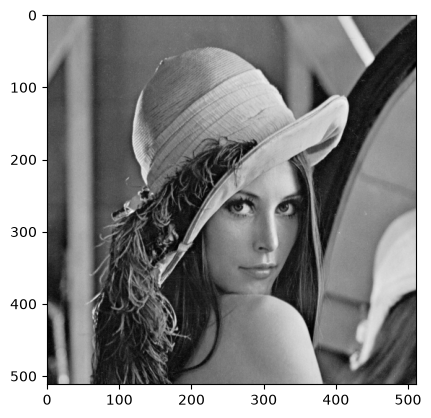

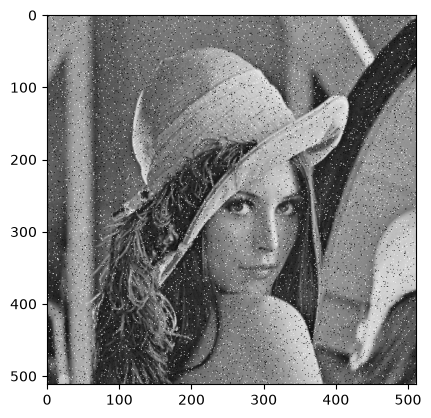

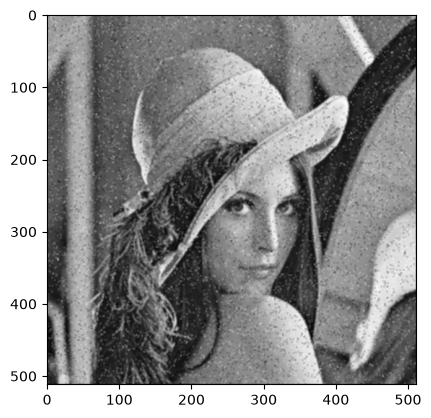

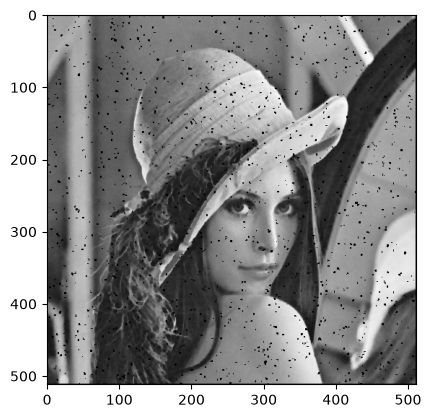

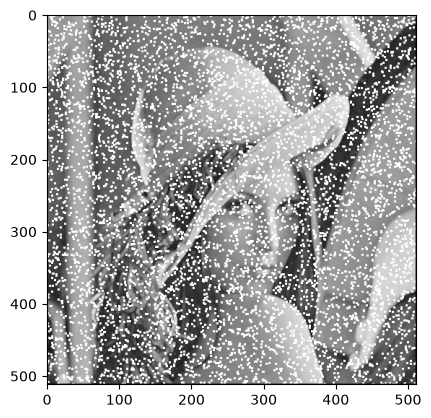

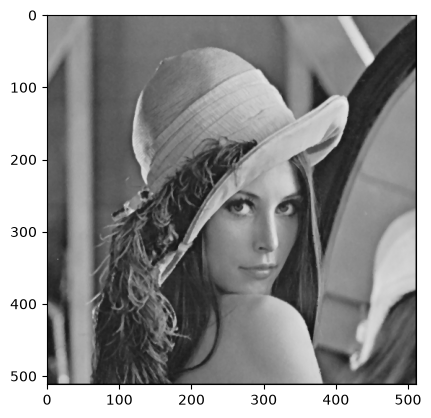

In [4]:
import numpy as np
import matplotlib as mpl
import math
from matplotlib import pyplot as plt
from skimage import io, color
from scipy import signal

# SNR = signal to noise ration
# 1 - 0 zgomot
# 0 - 100% zgomot
# 0.95 - 5% zgomot
def add_impulsive_noise(img, SNR):
    img_n = img.copy()
    h,w = img.shape
    noise_mask = np.random.choice((0,1,2), size=(h,w), p=[SNR, (1 - SNR) / 2., (1 - SNR) / 2.])
    img_n[noise_mask == 1] = 255
    img_n[noise_mask == 2] = 0
    return img_n

def mse(img, img_modif, capat):
    h,w = img.shape
    delta = img[capat:h-capat,capat:w-capat].astype(float) - img_modif[capat:h-capat,capat:w-capat].astype(float)
    delta = delta ** 2
    return np.sum(delta) / ((h-capat*2)*(w-capat*2))

def psnr(img, img_modif, capat):
    mseval = mse(img, img_modif, capat)
    return 20 * math.log10(255) - 10 * math.log10(mseval)
    
    
def rank_filter(vec, size, ordin):
    # sorteaza si alege valoarea de odrin corespunzator
    # parametrii: vecinatate, dimensiune filtru, ordin
    
    # transforma vecinatatea intr-un vector 1D
    values = np.reshape(vec, size**2)
    # sorteaza lista
    sorted = np.sort(values)
    # intoarce statistica de ordin k
    return sorted[ordin]

def apply_filter(img, size, ordin):
    # parametrii sunt imaginea, dimensiunea filtrului si ordinul
    h, w = img.shape
    capat = size // 2
    # pregatire imagine noua cu zero
    img_filtrata = np.zeros((h, w))

    # parcurgerea imaginii ( atentie la capete )
    for i in range(capat, h-capat):
        for j in range(capat, w-capat):
            # extrage vecinatate
            vec = img[i-capat:i+capat+1, j-capat:j+capat+1]
            # populeaza imaginea noua cu rezultatul filtrarii
            img_filtrata[i,j] = rank_filter(vec, vec.shape[0], ordin) 
    
    # intoarce noul rezultat
    return img_filtrata

# incarca lena.png
img = io.imread('lena.png')

# conversie nivele de gri si gama 0-255, uint 8
img = np.uint8(color.rgb2gray(img)*255)

# afisare imagine originala
plt.figure(),plt.imshow(img, cmap='gray')

# aplica zgomot
img_noise = add_impulsive_noise(img, 0.95)

# afiseaza imaginea cu zgomot
plt.figure(), plt.imshow(img_noise, cmap='gray')
# afiseaza MSE imagine cu zgomot 
print('MSE imagine cu zgomot: {}'.format(mse(img,img_noise,0)))

# setare dimensiune filtru
filter_size =3
capat = filter_size // 2

# aplicare filtrare mediere
mask = np.ones([filter_size, filter_size]) / (filter_size ** 2)
img_mediere = signal.convolve2d(img_noise, mask, mode='same')
# afiseaza imaginea filtrata prin filtru de mediere
plt.figure(), plt.imshow(img_mediere, cmap='gray')

# afiseaza MSE imagine cu zgomot filtrata prin filtru de mediere
print('MSE imagine filtrata liniar: {}'.format(mse(img, img_mediere, capat)))

# aplicare si afisare filtru ordin 1
img_rank1 = apply_filter(img_noise, filter_size, 1)
plt.figure(), plt.imshow(img_rank1, cmap='gray')

# aplicare si afisare filtru ordin max
img_rankm = apply_filter(img_noise, filter_size, filter_size**2-1)
plt.figure(), plt.imshow(img_rankm, cmap='gray')

# aplicare si afisare filtru median
img_median = apply_filter(img_noise, filter_size, filter_size**2 // 2)
plt.figure(), plt.imshow(img_median, cmap='gray')

# afiseaza MSE imagine filtrata cu filtru median
print('MSE imagine filtrata median: {}'.format(mse(img, img_median, capat)))
 

<h2> 5.2 L-Filtre </h2>
<p> 
    Scrieti o functie care implementeaza L-filtrul<br/>
    Scrieti o functie care parcurge imaginea si apeleaza L-filtrul pentru fiecare pixel<br/>
    Incarcati imaginea lena<br/>
    Aplicati zgomotul tip sare si piper<br/>
    Afisati imaginea cu zgomot<br/>
    Aplicati L-filtrul cu parametrii pentru filtrarea de mediere<br/>
    Calculati MSE<br/>
    Afisati imaginea rezultata<br/>
    Aplicati L-filtrul cu parametrii pentru filtrul median<br/>
    Calculati MSE<br/>
    Afisati imaginea rezultata<br/>
</p>


MSE imagine cu zgomot: 5.349254608154297
MSE imagine filtrata liniar: 144.6350971373783
MSE imagine filtrata median: 24.19052672049212


(<Figure size 640x480 with 1 Axes>,
 <matplotlib.image.AxesImage at 0x1388ad810>)

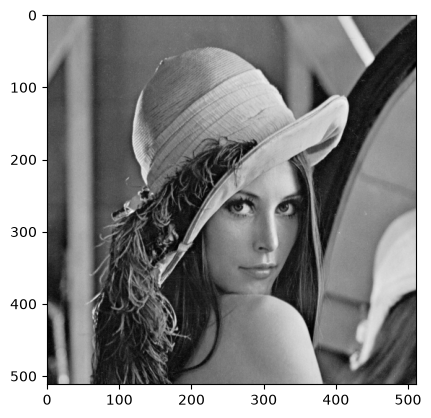

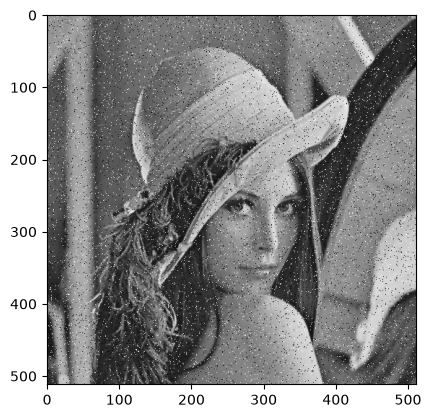

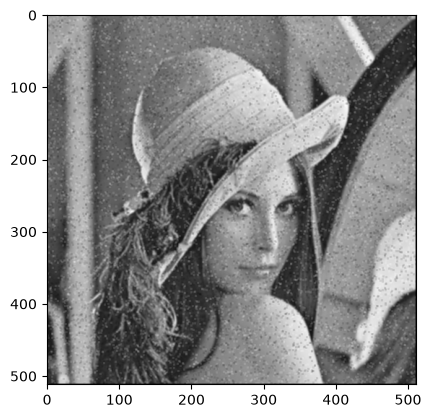

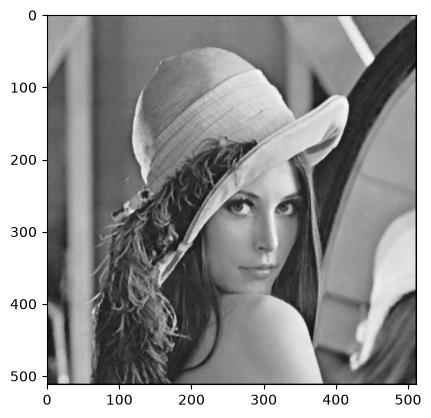

In [7]:
import numpy as np
import matplotlib as mpl
import math
from matplotlib import pyplot as plt
from skimage import io, color
from scipy import signal

# SNR = signal to noise ration
# 1 - 0 zgomot
# 0 - 100% zgomot
# 0.95 - 5% zgomot
def add_impulsive_noise(img, SNR):
    img_n = img.copy()
    h,w = img.shape
    noise_mask = np.random.choice((0,1,2), size=(h,w), p=[SNR, (1 - SNR) / 2., (1 - SNR) / 2.])
    img_n[noise_mask == 1] = 255
    img_n[noise_mask == 2] = 0
    return img_n

def mse(img, img_modif, capat):
    h,w = img.shape
    delta = img[capat:h-capat,capat:w-capat] - img_modif[capat:h-capat,capat:w-capat]
    delta = delta ** 2
    return np.sum(delta) / ((h-capat*2)*(w-capat*2))
    
    
def L_filter(vec, size, ponderi):
    # sorteaza si alege valoarea de odrin corespunzator
    # parametrii: vecinatate, dimensiune filtru, ponderi
    
    # transforma vecinatatea intr-un vector 1D
    sortedvalues = np.reshape(vec, size**2)
    # sorteaza lista
    sortedvalues = np.sort(sortedvalues)
    # asiguram ca ponderile sunt si ele un vector 1D
    ponderi = np.reshape(ponderi, size**2)
    # intoarce rezultat l-filtru ( suma valorilor sortate imultite cu ponderile)
    return np.sum(sortedvalues * ponderi)

def apply_L_filter(img,  size, ordin):
    # parametrii sunt imaginea, dimensiunea filtrului si ponderile
    h, w = img.shape
    capat = size // 2
    # pregatire imagine noua cu zero
    new_img = np.zeros((h, w))
    # parcurgerea imaginii ( atentie la capete )
    for i in range(capat, h-capat):
            for j in range(capat, w-capat):
                # extrage vecinatate
                vec = img[i-capat:i+capat+1, j-capat:j+capat+1]
                # populeaza imaginea noua cu rezultatul filtrarii
                new_img[i,j] = L_filter(vec, vec.shape[0], ordin)
    
    # intoarce noul rezultat
    return new_img

# incarca lena.png
img = io.imread('lena.png')

# conversie nivele de gri si gama 0-255, uint 8
img = np.uint8(color.rgb2gray(img)*255)

# afisare imagine originala
plt.figure(),plt.imshow(img, cmap='gray')

# aplica zgomot
img_noise = add_impulsive_noise(img, 0.95)

# afiseaza imaginea cu zgomot
plt.figure(), plt.imshow(img_noise, cmap='gray')
# afiseaza MSE imagine cu zgomot 
print('MSE imagine cu zgomot: {}'.format(mse(img,img_noise,0)))

# setare dimensiune filtru
filter_size =3
capat = filter_size // 2

# aplicare L-filtru mediere
# [1/9,1/9,1/9,1/9,1/9,1/9,1/9,1/9,1/9] in caz 3x3
# ganditi-va cum sa generalizati cu np.ones
# atentie, ponderile acum trebuiesc date ca un vector 1D

weights_mediere = 1/9*np.ones(filter_size**2)
img_mediere = apply_L_filter(img_noise, filter_size, weights_mediere)
# afisare MSE
print('MSE imagine filtrata liniar: {}'.format(mse(img, img_mediere, capat)))

# afisare imagine filtrata L-filtru mediere
plt.figure(), plt.imshow(img_mediere, cmap='gray')

# aplicare L-filtru median
# in caz 3x3 [0,0,0,0,1,0,0,0,0]
# in general, trebuie doar valoarea corespunzatoare medianului
# sa fie 1, puteti generalzia in functie de filter_size cu np.zeros
weights_median = np.zeros(filter_size**2)
weights_median[np.floor(filter_size**2//2).astype(np.uint8)] = 1
img_median = apply_L_filter(img_noise, filter_size, weights_median)
# afisare MSE
print('MSE imagine filtrata median: {}'.format(mse(img, img_median, capat)))

# afisare imagine filtrata L-filtru median
plt.figure(), plt.imshow(img_median, cmap='gray')

<h2> 5.3 Erodare </h2>
<p>
    Incarcati imaginea "morph.bmp"<br/>
    Convertiti imaginea in nivele de gri<br/>
    Afisati imaginea<br/>
    Definiti un element structurant care sa aiba ca efect disparitia liniilor orizontale din imagine prin erodare<br/>
    Aplicati erodarea<br/>
    Afisati rezultatul<br/>
    Definiti un element structurant care sa aiba ca efect subtierea elementelor imaginii<br/>
    Aplicati erodarea<br/>
    Afisati rezultatul<br/>
</p>


In [ ]:
import numpy as np
import matplotlib as mpl
from matplotlib import pyplot as plt
from skimage import io, color
import cv2

# incarcam imaginea "morph.bmp"
img = io.imread('morph.bmp')

# convertim imaginea in nivele de gri
img = np.float32(color.rgb2gray(img)*255)

# afisam imaginea
plt.figure(), plt.imshow(img, cmap='gray')

# definim un element structurant care sa aiba ca efect
# disparitia liniilor orizontale din imagine prin erodare
# ganditi-va la faptul ca elementul structurant trebuie sa fie
# inclus prin suprapunere in "obiect" atunci cand originea este 
# in pixelul curent, ca acel pixel sa fie pastrat
kernel1 = 
# aplicam erodarea
eroded1 = cv2.erode(img, kernel1)
# afisam rezultatul

# definim un element structurant care sa aiba ca efect subtierea
# elementelor imaginii pe ambele directii
# tipul de date trebuie sa fie 'uint8' pentru openCV
kernel2 = np.array([[,,,],[],[]], dtype='uint8')

# aplicam erodarea
eroded2 = 

# afisam rezultatul



<h2> 5.4 Dilatare </h2>
<p>
     Incarcati imaginea "morph.bmp"<br/>
    Convertiti imaginea in nivele de gri<br/>
    Afisati imaginea<br/>
    Definiti un element structurant care sa aiba ca efect igrosarea pe verticala a liniilor prin dilatare<br/>
    Aplicati dilatarea<br/>
    Afisati rezultatul<br/>
    Definiti un element structurant care sa aiba ca efect ingrosarea elementelor din imagine<br/>
    Aplicati dilatarea<br/>
    Afisati rezultatul<br/>
</p>

In [ ]:
import numpy as np
import matplotlib as mpl
from matplotlib import pyplot as plt
from skimage import io, color
import cv2

# incarcam imaginea "morph.bmp"
img = io.imread('morph.bmp')

# convertim imaginea in nivele de gri


# afisam imaginea


# definim un element structurant care sa aiba ca efect
# igrosarea pe verticala a liniilor prin dilatare
# considerati ca pentru dilatare, este suficient sa exista o suprapunere de 1 
# singur pixel cu elementul structurant pentru ca originea curenta sa fie 
# umpluta
kernel1 = 
# aplicam dilatarea
dilated1 = cv2.dilate(img, kernel1)
# afisam rezultatul

# definim un element structurant care sa aiba ca efectingrosarea 
# elementelor din imagine
kernel2 = np.array([[],[],[]], dtype='uint8')

# aplicam dilatarea
dilated2 = 

# afisam rezultatul
plt.figure(), plt.imshow(dilated2, cmap='gray')

